In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Localiza o CSV (na mesma pasta do notebook ou em data/raw)
ARQ = next(p for p in [Path("vendas_bigdata_2026.csv"),
                       Path("data/raw/vendas_bigdata_2026.csv")] if p.exists())

PASTA_RESULTADO = Path("resultado")
PASTA_RESULTADO.mkdir(exist_ok=True)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})
print("Arquivo de entrada:", ARQ.resolve())

Arquivo de entrada: C:\Users\LUCAS\Documents\projeto_vendas\vendas_bigdata_2026.csv


In [3]:
df = pd.read_csv(ARQ)

print("=== df.head() ===")
display(df.head())
print("\n=== df.shape ===")
print(df.shape)
print("\n=== df.info() ===")
df.info()
print("\n=== df.dtypes ===")
print(df.dtypes)
print("\n=== df.isna().sum() ===")
print(df.isna().sum())
print("\n=== df.duplicated().sum() ===")
print(df.duplicated().sum())

print("\nValores distintos em 'regiao' (antes da padronização):")
print(df["regiao"].value_counts(dropna=False).to_string())

=== df.head() ===


,pedido_id,data,cliente_id,categoria,produto,regiao,canal,forma_pagamento,quantidade,preco_unitario,desconto_percentual,valor,frete,avaliacao,devolvido
0,PED001179,2026-07-22,CLI0271,Games,Joystick,Norte,App,Cartão de crédito,1,437.67,10,393.90,0.00,NaN,Não
1,PED000866,2026-09-01,CLI0132,Eletrônicos,Headset,Sudeste,App,Pix,2,208.55,5,396.25,0.00,NaN,Não
2,PED000102,2026-09-15,CLI0198,Eletrônicos,Webcam,Norte,Site,Pix,4,298.89,5,1135.78,0.00,NaN,Não
3,PED000440,2026-05-13,CLI0244,Games,Joystick,NaN,App,Pix,2,388.42,0,776.84,0.00,3.3,Não
4,PED000059,2026-05-30,CLI0140,Casa,Ventilador,Sudeste,App,Cartão de crédito,1,222.85,0,222.85,27.58,NaN,Não



=== df.shape ===
(1200, 15)

=== df.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   pedido_id            1200 non-null   str    
 1   data                 1199 non-null   str    
 2   cliente_id           1200 non-null   str    
 3   categoria            1192 non-null   str    
 4   produto              1200 non-null   str    
 5   regiao               1188 non-null   str    
 6   canal                1200 non-null   str    
 7   forma_pagamento      1200 non-null   str    
 8   quantidade           1200 non-null   int64  
 9   preco_unitario       1200 non-null   float64
 10  desconto_percentual  1200 non-null   int64  
 11  valor                1200 non-null   float64
 12  frete                1200 non-null   float64
 13  avaliacao            854 non-null    float64
 14  devolvido            1200 non-null   str    
dtypes

In [4]:
TOLERANCIA = 0.02  # 'valor' está arredondado a 2 casas
REGIOES_VALIDAS = {"Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"}

dados = pd.read_csv(ARQ)
n_original = len(dados)

# --- 1. Datas: converter e identificar inválidas --------------------------
dados["data_original"] = dados["data"]
dados["data"] = pd.to_datetime(dados["data"], format="%Y-%m-%d", errors="coerce")
datas_invalidas = dados.loc[dados["data"].isna(), ["pedido_id", "data_original"]]
print("Datas inválidas:")
display(datas_invalidas.fillna("<ausente>"))

# --- 2. Duplicatas ----------------------------------------------------------
colunas_dup = [c for c in dados.columns if c != "data_original"]
n_dup = int(dados.duplicated(subset=colunas_dup).sum())
dados = dados.drop_duplicates(subset=colunas_dup, keep="first").copy()
assert dados["pedido_id"].is_unique, "pedido_id ainda duplicado"
print(f"Duplicatas removidas: {n_dup}")

# --- 3. Valores ausentes -----------------------------------------------------
print("\nAusentes antes do tratamento:")
print(dados.isna().sum()[lambda s: s > 0].to_string())

assert (dados.dropna(subset=["categoria"]).groupby("produto")["categoria"].nunique() == 1).all()
mapa_categoria = (dados.dropna(subset=["categoria"])
                  .groupby("produto")["categoria"].agg(lambda s: s.mode().iat[0]))
ausente_cat = dados["categoria"].isna()
dados.loc[ausente_cat, "categoria"] = dados.loc[ausente_cat, "produto"].map(mapa_categoria)
print(f"\nCategorias recuperadas via produto: {int(ausente_cat.sum())}")

# --- 4. Padronizar região ----------------------------------------------------
dados["regiao"] = dados["regiao"].str.strip().str.title()
regiao_ausente = dados["regiao"].isna()
dados.loc[regiao_ausente, "regiao"] = "Não informada"
inesperadas = set(dados["regiao"].unique()) - REGIOES_VALIDAS - {"Não informada"}
assert not inesperadas, f"Regiões inesperadas: {inesperadas}"
print("Regiões após padronização:", sorted(dados["regiao"].unique()))

# --- 5. Quantidade <= 0 e preço <= 0 ----------------------------------------
dados["flag_preco_invalido"] = dados["preco_unitario"] <= 0
dados["flag_quantidade_invalida"] = dados["quantidade"] <= 0
print(f"\npreco_unitario <= 0: {int(dados['flag_preco_invalido'].sum())}")
print(f"quantidade <= 0: {int(dados['flag_quantidade_invalida'].sum())}")

# Preço negativo: corrige com abs() somente se 'valor' confirmar
dados["preco_corrigido"] = dados["preco_unitario"]
conf_preco = dados["flag_preco_invalido"] & (
    (dados["quantidade"] * dados["preco_unitario"].abs()
     * (1 - dados["desconto_percentual"] / 100) - dados["valor"]).abs() <= TOLERANCIA)
dados.loc[conf_preco, "preco_corrigido"] = dados.loc[conf_preco, "preco_unitario"].abs()
print(f"Preços corrigidos (inversão de sinal): {int(conf_preco.sum())}")

# Quantidade <= 0: infere a partir de valor / preço líquido
preco_liq = dados["preco_corrigido"] * (1 - dados["desconto_percentual"] / 100)
qtd_implicita = dados["valor"] / preco_liq
inteiro = (qtd_implicita - qtd_implicita.round()).abs() < 0.02
conf_qtd = dados["flag_quantidade_invalida"] & inteiro & qtd_implicita.round().between(1, 10)
dados["quantidade_corrigida"] = dados["quantidade"]
dados.loc[conf_qtd, "quantidade_corrigida"] = qtd_implicita[conf_qtd].round().astype(int)
print(f"Quantidades corrigidas via valor: {int(conf_qtd.sum())}")

ainda_invalido = (dados["preco_corrigido"] <= 0) | (dados["quantidade_corrigida"] <= 0)

# etapa de consistencia operacional
dados["valor_esperado"] = (dados["quantidade_corrigida"] * dados["preco_corrigido"]
                           * (1 - dados["desconto_percentual"] / 100)).round(2)
dados["diferenca_valor"] = (dados["valor"] - dados["valor_esperado"]).round(2)
dados["flag_valor_inconsistente"] = dados["diferenca_valor"].abs() > TOLERANCIA
dados["valor_confiavel"] = ~dados["flag_valor_inconsistente"] & ~ainda_invalido

print(f"\nPedidos com valor incoerente após as correções: "
      f"{int(dados['flag_valor_inconsistente'].sum())}")
display(dados.loc[dados["flag_valor_inconsistente"],
                  ["pedido_id", "quantidade", "preco_unitario", "desconto_percentual",
                   "valor", "valor_esperado"]])

# --- 6. Tipos finais e exportação -------------------------------------------
dados["devolvido"] = dados["devolvido"].map({"Sim": True, "Não": False})
dados = dados.sort_values("pedido_id").reset_index(drop=True)

ARQ_TRATADO = PASTA_RESULTADO / "vendas_tratadas.csv"
dados.to_csv(ARQ_TRATADO, index=False, encoding="utf-8")

validas = dados.loc[dados["valor_confiavel"]].copy()
print(f"\nRegistros originais: {n_original} | finais: {len(dados)} | "
      f"com valor confiável: {len(validas)}")
print(f"Faturamento validado: R$ {validas['valor'].sum():,.2f}")

Datas inválidas:


,pedido_id,data_original
237,PED000543,<ausente>
417,PED000669,2026-02-30
470,PED000772,31/11/2026
713,PED000808,data_invalida
1110,PED000379,2026-13-05


Duplicatas removidas: 8

Ausentes antes do tratamento:
data               5
categoria          8
regiao            12
avaliacao        343
data_original      1

Categorias recuperadas via produto: 8
Regiões após padronização: ['Centro-Oeste', 'Nordeste', 'Norte', 'Não informada', 'Sudeste', 'Sul']

preco_unitario <= 0: 5
quantidade <= 0: 5
Preços corrigidos (inversão de sinal): 5
Quantidades corrigidas via valor: 5

Pedidos com valor incoerente após as correções: 9


,pedido_id,quantidade,preco_unitario,desconto_percentual,valor,valor_esperado
10,PED000821,2,301.83,0,905.49,603.66
42,PED001109,1,171.52,5,244.41,162.94
324,PED001120,1,84.39,5,120.25,80.17
509,PED000006,3,240.64,5,1028.73,685.82
756,PED000086,2,193.71,0,193.71,387.42
878,PED001174,1,184.16,15,78.27,156.54
907,PED001129,4,280.22,10,504.39,1008.79
997,PED000298,3,255.60,10,345.06,690.12
1001,PED000946,1,94.57,15,160.76,80.38



Registros originais: 1200 | finais: 1192 | com valor confiável: 1183
Faturamento validado: R$ 543,133.51


In [5]:
# 1. Região com maior faturamento
resumo_regional_validado = (
    validas.groupby("regiao")
    .agg(faturamento_total=("valor", "sum"),
         pedidos=("pedido_id", "nunique"),
         itens=("quantidade_corrigida", "sum"))
    .sort_values("faturamento_total", ascending=False)
)
resumo_regional_validado["participacao_%"] = (
    100 * resumo_regional_validado["faturamento_total"]
    / resumo_regional_validado["faturamento_total"].sum()).round(1)
print("1) Faturamento por região")
display(resumo_regional_validado.round(2))

# 2. Cinco produtos com maior faturamento
top_produtos = (validas.groupby("produto")["valor"].sum()
                .sort_values(ascending=False).head(5).round(2))
print("2) Top 5 produtos por faturamento")
display(top_produtos.to_frame("faturamento"))

# 3. Canal com maior faturamento
por_canal = validas.groupby("canal")["valor"].sum().sort_values(ascending=False).round(2)
print("3) Faturamento por canal")
display(por_canal.to_frame("faturamento"))

# 4. Forma de pagamento mais utilizada (número de pedidos)
pagamento = dados["forma_pagamento"].value_counts()
print("4) Forma de pagamento (nº de pedidos)")
display(pagamento.to_frame("pedidos"))

# 5. Evolução mensal
mensal = (validas.dropna(subset=["data"])
          .groupby(validas["data"].dt.to_period("M"))["valor"].sum().round(2))
print("5) Faturamento mensal")
display(mensal.to_frame("faturamento"))
print(f"Última data na base: {validas['data'].max().date()} (o último mês é parcial)")

print(f"\nTaxa de devolução: {dados['devolvido'].mean() * 100:.1f}%")

1) Faturamento por região


,faturamento_total,pedidos,itens,participacao_%
regiao,,,,
Sudeste,222568.07,510,970,41.0
Sul,117255.08,236,474,21.6
Nordeste,109601.16,231,457,20.2
Centro-Oeste,49829.76,111,217,9.2
Norte,37322.92,83,160,6.9
Não informada,6556.52,12,25,1.2


2) Top 5 produtos por faturamento


,faturamento
produto,
Mesa,60781.65
Cadeira,59544.32
SSD 1TB,43192.45
Aspirador,41924.48
Joystick,34735.11


3) Faturamento por canal


,faturamento
canal,
Site,277560.54
App,189861.09
Loja física,75711.88


4) Forma de pagamento (nº de pedidos)


,pedidos
forma_pagamento,
Pix,494
Cartão de crédito,459
Cartão de débito,125
Boleto,114


5) Faturamento mensal


,faturamento
data,
2026-01,49913.25
2026-02,47292.85
2026-03,56137.14
2026-04,48925.86
2026-05,54810.54
2026-06,41379.12
2026-07,68399.03
2026-08,48821.57
2026-09,60834.90


Última data na base: 2026-11-01 (o último mês é parcial)

Taxa de devolução: 6.3%


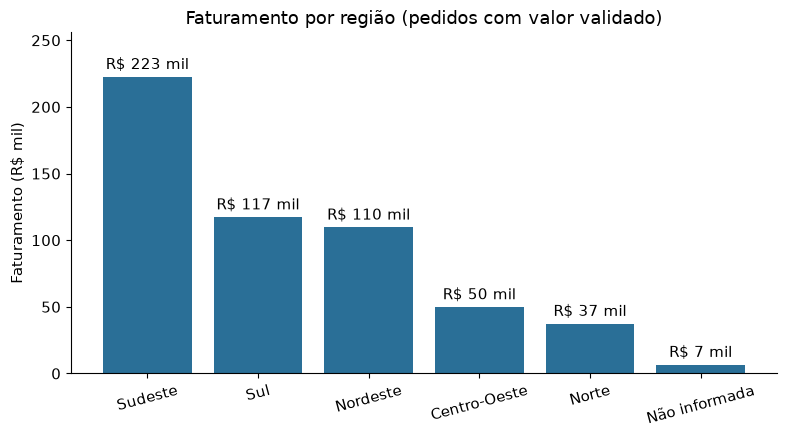

In [6]:
# Gráfico 1 - faturamento por região
fig, ax = plt.subplots(figsize=(8, 4.5))
valores = resumo_regional_validado["faturamento_total"] / 1000
barras = ax.bar(valores.index, valores.values, color="#2a6f97")
ax.bar_label(barras, fmt="R$ %.0f mil", padding=3)
ax.set_title("Faturamento por região (pedidos com valor validado)")
ax.set_ylabel("Faturamento (R$ mil)")
ax.set_ylim(0, valores.max() * 1.15)
plt.xticks(rotation=15)
fig.tight_layout()
plt.show()

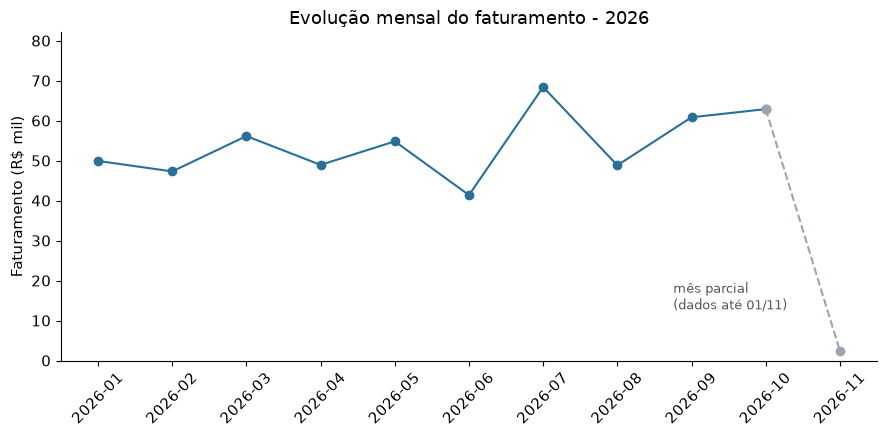

In [7]:
# Gráfico 2 - evolução mensal (último mês é parcial)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = mensal.index.astype(str)
ax.plot(x[:-1], mensal.values[:-1] / 1000, marker="o", color="#2a6f97")
ax.plot(x[-2:], mensal.values[-2:] / 1000, marker="o", linestyle="--", color="#9aa5b1")
ax.annotate("mês parcial\n(dados até 01/11)", (x[-1], mensal.values[-1] / 1000),
            textcoords="offset points", xytext=(-120, 30), fontsize=9, color="#555")
ax.set_title("Evolução mensal do faturamento - 2026")
ax.set_ylabel("Faturamento (R$ mil)")
ax.set_ylim(0, mensal.max() / 1000 * 1.2)
plt.xticks(rotation=45)
fig.tight_layout()
plt.show()

In [8]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("vendas_bigdata_2026")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "4")  # dataset pequeno
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df_spark = (spark.read
            .option("header", True)
            .option("inferSchema", True)
            .csv(str(ARQ_TRATADO.resolve())))
df_spark.printSchema()

resumo_spark = (
    df_spark
    .filter(F.col("valor_confiavel") == True)                      # transformação
    .groupBy("regiao")                                             # transformação (shuffle)
    .agg(F.round(F.sum("valor"), 2).alias("faturamento_total"),
         F.countDistinct("pedido_id").alias("pedidos"),
         F.sum("quantidade_corrigida").alias("itens_vendidos"))    # transformação
    .orderBy(F.col("faturamento_total").desc())                    # transformação (sort)
)

resumo_spark.show()          # AÇÃO: é aqui que o processamento acontece
resumo_spark.explain()       # plano físico: note o Exchange (shuffle)

# Exporta o resultado pedido na estrutura de entrega
resumo_pd = resumo_spark.toPandas()
resumo_pd.to_csv(PASTA_RESULTADO / "resumo_regioes.csv", index=False, encoding="utf-8-sig")

total_spark = resumo_pd["faturamento_total"].sum()
print(f"Faturamento total no Spark: R$ {total_spark:,.2f}")
print(f"Faturamento total no Pandas: R$ {validas['valor'].sum():,.2f}")

c:\Users\LUCAS\Documents\projeto_vendas\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


root
 |-- pedido_id: string (nullable = true)
 |-- data: date (nullable = true)
 |-- cliente_id: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- produto: string (nullable = true)
 |-- regiao: string (nullable = true)
 |-- canal: string (nullable = true)
 |-- forma_pagamento: string (nullable = true)
 |-- quantidade: integer (nullable = true)
 |-- preco_unitario: double (nullable = true)
 |-- desconto_percentual: integer (nullable = true)
 |-- valor: double (nullable = true)
 |-- frete: double (nullable = true)
 |-- avaliacao: double (nullable = true)
 |-- devolvido: boolean (nullable = true)
 |-- data_original: string (nullable = true)
 |-- flag_preco_invalido: boolean (nullable = true)
 |-- flag_quantidade_invalida: boolean (nullable = true)
 |-- preco_corrigido: double (nullable = true)
 |-- quantidade_corrigida: integer (nullable = true)
 |-- valor_esperado: double (nullable = true)
 |-- diferenca_valor: double (nullable = true)
 |-- flag_valor_inconsistente: 

c:\Users\LUCAS\Documents\projeto_vendas\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\LUCAS\Documents\projeto_vendas\.venv\Lib\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Faturamento total no Spark: R$ 543,133.51
Faturamento total no Pandas: R$ 543,133.51


In [9]:
df_spark.createOrReplaceTempView("vendas")

devolucoes_categoria = spark.sql("""
    SELECT categoria,
           COUNT(*)                                             AS pedidos,
           SUM(CASE WHEN devolvido = true THEN 1 ELSE 0 END)    AS devolvidos,
           ROUND(100.0 * SUM(CASE WHEN devolvido = true THEN 1 ELSE 0 END)
                 / COUNT(*), 2)                                 AS taxa_devolucao_pct,
           ROUND(SUM(CASE WHEN devolvido = true THEN valor ELSE 0 END), 2)
                                                                AS valor_devolvido
    FROM vendas
    WHERE valor_confiavel = true
    GROUP BY categoria
    ORDER BY taxa_devolucao_pct DESC
""")
devolucoes_categoria.show()

+-----------+-------+----------+------------------+---------------+
|  categoria|pedidos|devolvidos|taxa_devolucao_pct|valor_devolvido|
+-----------+-------+----------+------------------+---------------+
|Eletrônicos|    244|        19|              7.79|        8182.17|
|       Casa|    238|        18|              7.56|         9116.1|
| Escritório|    225|        14|              6.22|       10148.97|
|      Games|    235|        12|              5.11|        5238.81|
| Acessórios|    241|        11|              4.56|         1739.4|
+-----------+-------+----------+------------------+---------------+



In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Exemplo ilustrativo: prever se o pedido será devolvido
X = validas[["quantidade_corrigida", "preco_corrigido", "desconto_percentual", "frete"]]
y = validas["devolvido"].astype(int)

# 1) Divide PRIMEIRO (estratificado, pois devoluções são minoria)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 2) Scaler + modelo no mesmo Pipeline: fit() aprende a escala só no treino
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
pipe.fit(X_train, y_train)
auc_teste = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
print(f"AUC no teste (pipeline correto): {auc_teste:.3f}")

# 3) Validação cruzada: o scaler é re-ajustado dentro de cada fold
cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
print(f"AUC validação cruzada (5 folds): {cv.mean():.3f} +/- {cv.std():.3f}")

AUC no teste (pipeline correto): 0.348
AUC validação cruzada (5 folds): 0.473 +/- 0.073


In [11]:
spark.stop()